In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
DATA_PATH = Path("../data/processed/train.csv")

In [3]:
df = pd.read_csv(DATA_PATH)

In [4]:
df.head()

,vehicle_speed,leader_speed,leader_distance,relative_speed,time_to_collision,speed_limit,v2v_emergency_flag,target_speed
0,7.23,3.14,74.04,4.08,18.13,8.33,0,8.33
1,10.60,3.02,71.20,7.59,9.38,13.89,0,9.35
2,10.50,14.06,11.33,-3.56,99.00,13.89,0,4.09
3,4.95,6.60,58.29,-1.65,99.00,22.22,0,8.53
4,0.00,4.84,65.18,-4.84,99.00,13.89,0,0.00


In [5]:
df.shape

(40000, 8)

In [6]:
print(df.isnull().sum())
print(df.dtypes)
df.describe().T

vehicle_speed         0
leader_speed          0
leader_distance       0
relative_speed        0
time_to_collision     0
speed_limit           0
v2v_emergency_flag    0
target_speed          0
dtype: int64
vehicle_speed         float64
leader_speed          float64
leader_distance       float64
relative_speed        float64
time_to_collision     float64
speed_limit           float64
v2v_emergency_flag      int64
target_speed          float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
vehicle_speed,40000.0,7.417483,5.377955,0.00,3.1900,6.340,10.73,22.99
leader_speed,40000.0,7.445431,5.434385,0.00,3.1900,6.370,10.72,23.82
leader_distance,40000.0,40.932279,22.521511,0.50,21.2100,40.955,60.41,83.12
relative_speed,40000.0,-0.027950,6.524128,-22.47,-3.9400,-0.030,3.94,22.40
time_to_collision,40000.0,59.675635,43.592820,0.10,9.5475,99.000,99.00,99.00
speed_limit,40000.0,14.834709,5.701200,8.33,8.3300,13.890,22.22,22.22
v2v_emergency_flag,40000.0,0.199600,0.399705,0.00,0.0000,0.000,0.00,1.00
target_speed,40000.0,5.762188,5.293597,0.00,1.3200,4.810,8.33,22.22


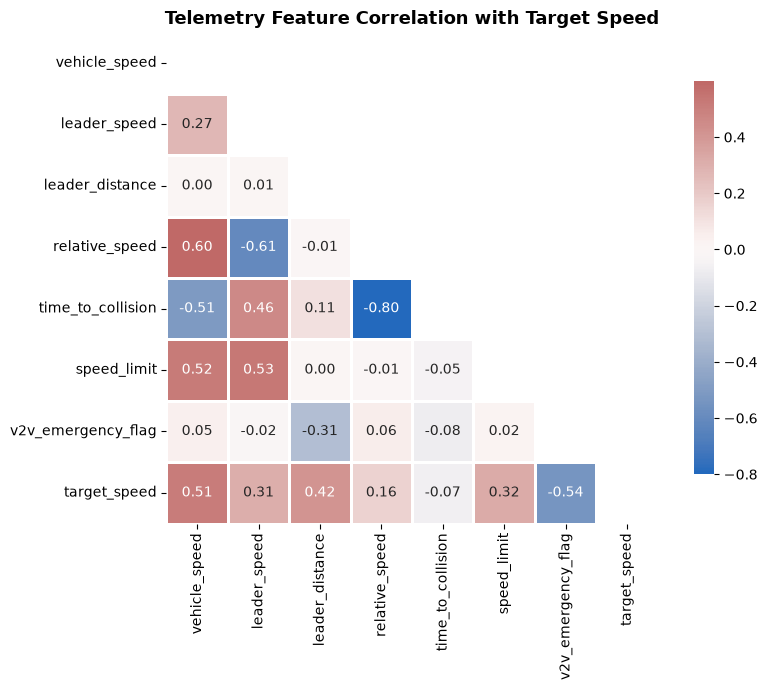

In [7]:
plt.figure(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    center=0,
    square=True, 
    linewidths=0.8,
    cbar_kws={"shrink": 0.8}
)
plt.title("Telemetry Feature Correlation with Target Speed", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()

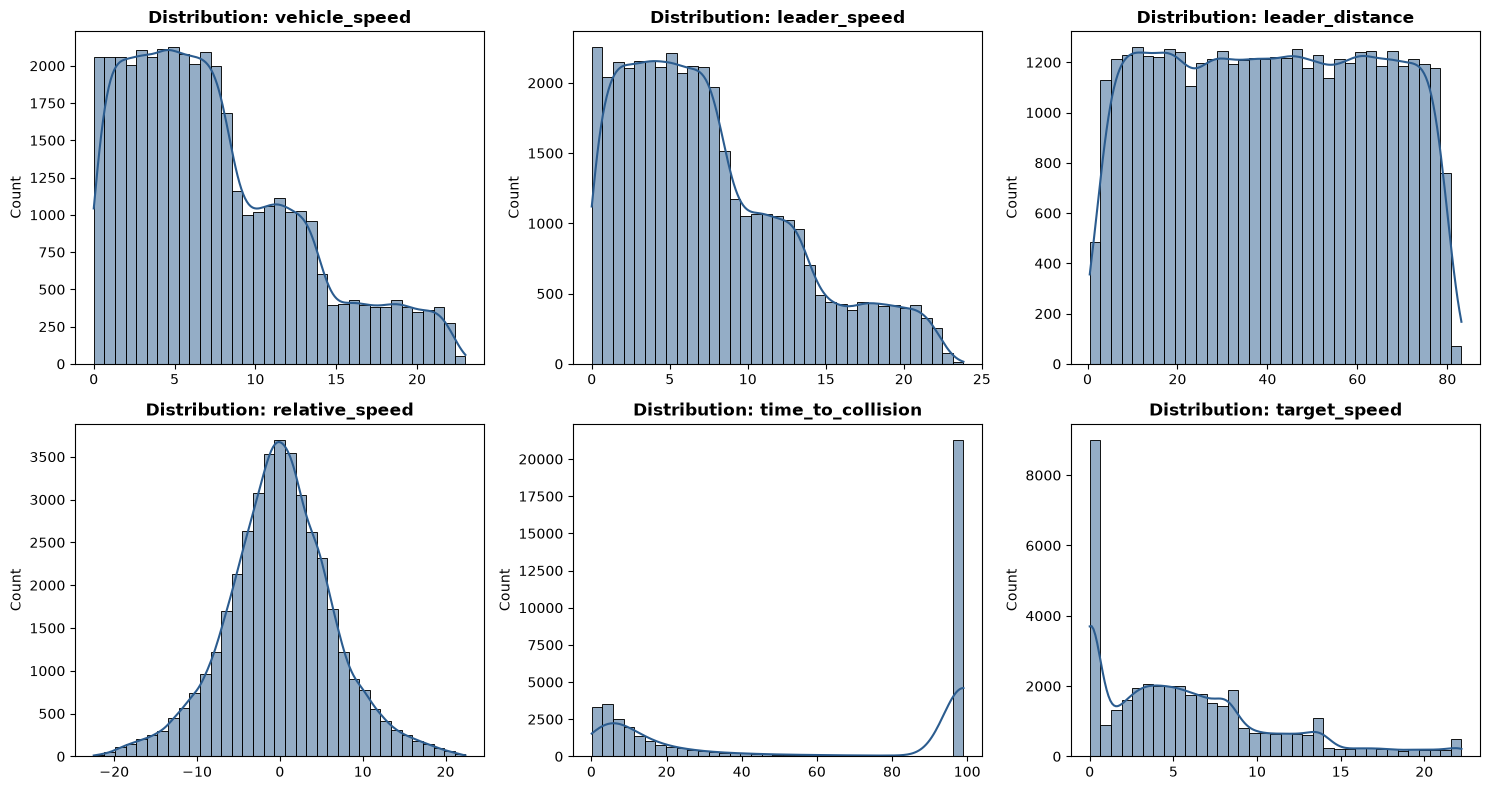

In [8]:
features = [
    "vehicle_speed", "leader_speed", "leader_distance", 
    "relative_speed", "time_to_collision", "target_speed"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=35, color="#2b5c8f")
    axes[i].set_title(f"Distribution: {col}", weight="bold")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

Total Emergency Braking Samples: 3454


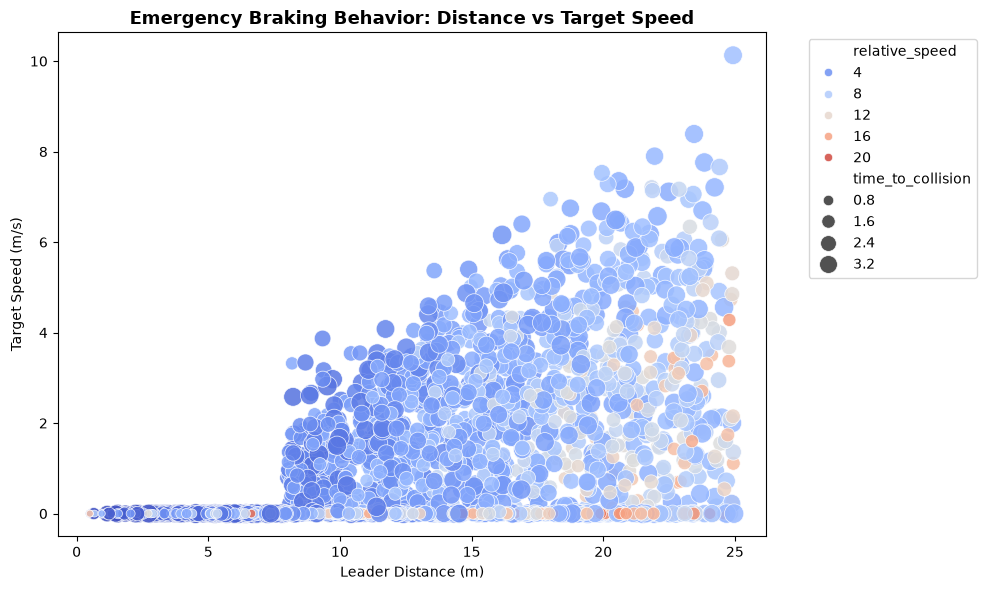

In [9]:
# Emergency braking zone filter (TTC < 4s & Distance < 25m)
emergency_mask = (df["time_to_collision"] < 4.0) & (df["leader_distance"] < 25.0)
emergency_samples = df[emergency_mask]

print(f"Total Emergency Braking Samples: {len(emergency_samples)}")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=emergency_samples,
    x="leader_distance",
    y="target_speed",
    hue="relative_speed",
    palette="coolwarm",
    size="time_to_collision",
    sizes=(25, 200),
    alpha=0.85
)
plt.title("Emergency Braking Behavior: Distance vs Target Speed", fontsize=13, weight="bold")
plt.xlabel("Leader Distance (m)")
plt.ylabel("Target Speed (m/s)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

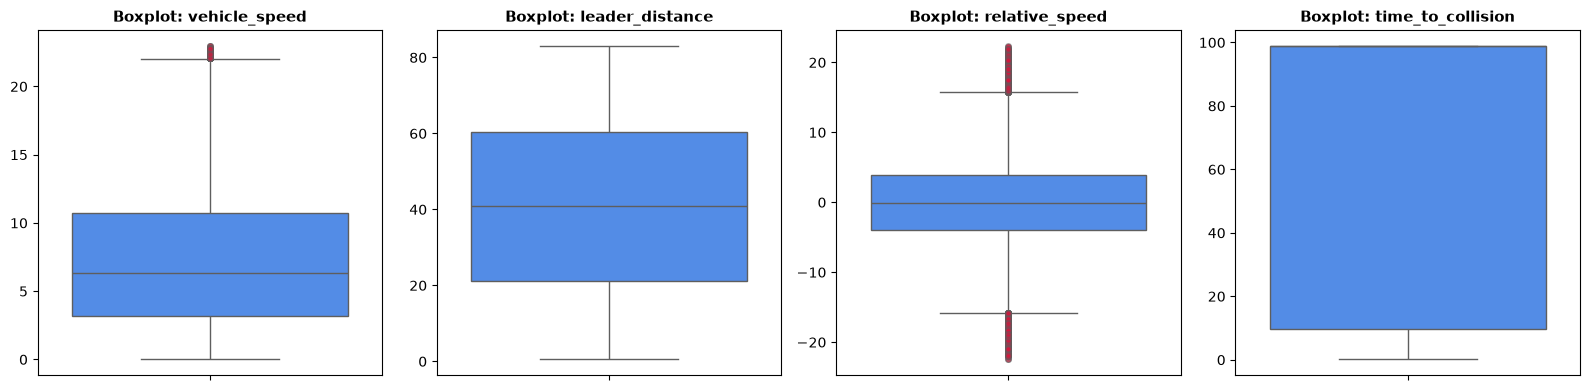

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
box_cols = ["vehicle_speed", "leader_distance", "relative_speed", "time_to_collision"]

for i, col in enumerate(box_cols):
    sns.boxplot(
        y=df[col], 
        ax=axes[i], 
        color="#3a86ff", 
        flierprops=dict(markerfacecolor='crimson', markersize=4, alpha=0.5)
    )
    axes[i].set_title(f"Boxplot: {col}", weight="bold", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()